# Unsupervised vs Supervised Learning – Assignment Notebook
Each task is given as a **Definition** cell followed directly by its answer cells.

**Files created alongside this notebook:** `app_users_dataset.csv`, `products_dataset.csv`, `mall_customers_sample.csv`

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
pd.set_option('display.width', 150)

**1.**  
Write a short Python script that generates a random dataset of 10 users, each with two features: number of daily app opens and average session duration (in minutes). Print the dataset as a list of dictionaries.

In [2]:
random.seed(42)

def generate_users(n=10):
    return [
        {
            "user_id": i + 1,
            "daily_app_opens": random.randint(1, 40),                 # times per day
            "avg_session_minutes": round(random.uniform(0.5, 30), 1)  # minutes per session
        }
        for i in range(n)
    ]

users = generate_users(10)
print(users)                      # list of dictionaries (required output)

[{'user_id': 1, 'daily_app_opens': 8, 'avg_session_minutes': 1.2}, {'user_id': 2, 'daily_app_opens': 18, 'avg_session_minutes': 7.7}, {'user_id': 3, 'daily_app_opens': 9, 'avg_session_minutes': 22.2}, {'user_id': 4, 'daily_app_opens': 35, 'avg_session_minutes': 3.1}, {'user_id': 5, 'daily_app_opens': 28, 'avg_session_minutes': 1.4}, {'user_id': 6, 'daily_app_opens': 6, 'avg_session_minutes': 6.9}, {'user_id': 7, 'daily_app_opens': 33, 'avg_session_minutes': 18.3}, {'user_id': 8, 'daily_app_opens': 36, 'avg_session_minutes': 6.4}, {'user_id': 9, 'daily_app_opens': 35, 'avg_session_minutes': 12.9}, {'user_id': 10, 'daily_app_opens': 29, 'avg_session_minutes': 17.9}]


In [3]:
# Pretty view + save to CSV so it can be reused
users_df = pd.DataFrame(users)
users_df.to_csv("app_users_dataset.csv", index=False)
users_df

,user_id,daily_app_opens,avg_session_minutes
0,1,8,1.2
1,2,18,7.7
2,3,9,22.2
3,4,35,3.1
4,5,28,1.4
5,6,6,6.9
6,7,33,18.3
7,8,36,6.4
8,9,35,12.9
9,10,29,17.9


**2.**  
Create a table comparing supervised and unsupervised learning in at least 4 points, using real-world app examples (like Instagram feed ranking for supervised, Spotify playlist grouping for unsupervised).

In [4]:
comparison = pd.DataFrame({
    "Point": ["Data used", "Goal", "Typical algorithms", "Evaluation", "Human effort"],
    "Supervised Learning": [
        "Labeled data (input + known output). Ex: Instagram posts labeled with 'user liked / didn't like'.",
        "Predict a known target. Ex: Instagram feed ranking predicts the probability you will like/comment on a post.",
        "Linear/Logistic Regression, Decision Trees, Random Forest, Neural Networks.",
        "Clear metrics against true labels: accuracy, precision, recall, RMSE.",
        "High – labels must be collected/annotated (e.g., click / no-click logs)."],
    "Unsupervised Learning": [
        "Unlabeled data (inputs only). Ex: Spotify listening histories with no 'correct' group given.",
        "Discover hidden structure. Ex: Spotify groups songs/listeners into similar-taste clusters for auto playlists.",
        "K-Means, Hierarchical Clustering, DBSCAN, PCA, Association Rules.",
        "No ground truth: silhouette score, inertia (elbow), business interpretation.",
        "Lower labeling effort, but needs human interpretation of the discovered groups."]
})
comparison.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index")

Point,Supervised Learning,Unsupervised Learning
Data used,Labeled data (input + known output). Ex: Instagram posts labeled with 'user liked / didn't like'.,Unlabeled data (inputs only). Ex: Spotify listening histories with no 'correct' group given.
Goal,Predict a known target. Ex: Instagram feed ranking predicts the probability you will like/comment on a post.,Discover hidden structure. Ex: Spotify groups songs/listeners into similar-taste clusters for auto playlists.
Typical algorithms,"Linear/Logistic Regression, Decision Trees, Random Forest, Neural Networks.","K-Means, Hierarchical Clustering, DBSCAN, PCA, Association Rules."
Evaluation,"Clear metrics against true labels: accuracy, precision, recall, RMSE.","No ground truth: silhouette score, inertia (elbow), business interpretation."
Human effort,"High – labels must be collected/annotated (e.g., click / no-click logs).","Lower labeling effort, but needs human interpretation of the discovered groups."


| Point | Supervised Learning | Unsupervised Learning |
|---|---|---|
| **Data used** | Labeled (Instagram posts + like/no-like) | Unlabeled (Spotify listening logs) |
| **Goal** | Predict a known outcome (feed ranking) | Find hidden groups (playlist/taste clusters) |
| **Algorithms** | Regression, Decision Trees, Neural Nets | K-Means, DBSCAN, PCA |
| **Evaluation** | Accuracy, precision, recall vs true labels | Silhouette, elbow, business sense |
| **Human effort** | High – labeling needed | Lower labeling, more interpretation |

**3.**  
Given a list of 8 products with their price and number of reviews, use any method (even manual grouping) to segment them into 2-3 clusters based on similarity. Explain your reasoning for each cluster.

*Hint: Think about which products are similar in both price and popularity (reviews).*

In [5]:
# 8 products: price (Rs) and number of reviews (popularity)
products = pd.DataFrame({
    "product":  ["USB Cable", "Phone Case", "Wired Earphones", "Bluetooth Speaker",
                 "Smartwatch", "Tablet", "Camera", "Laptop"],
    "price":    [199, 299, 499, 1999, 2499, 32000, 45000, 65000],
    "reviews":  [45000, 52000, 38000, 9000, 7500, 1500, 600, 800]
})
products.to_csv("products_dataset.csv", index=False)
products

,product,price,reviews
0,USB Cable,199,45000
1,Phone Case,299,52000
2,Wired Earphones,499,38000
3,Bluetooth Speaker,1999,9000
4,Smartwatch,2499,7500
5,Tablet,32000,1500
6,Camera,45000,600
7,Laptop,65000,800


### Manual reasoning first
Looking at the numbers: some items are **very cheap with huge review counts**, some are **mid-priced with moderate reviews**, and some are **very expensive with few reviews**. So 3 natural groups.

In [6]:
# Price spans 199 -> 65,000, so log-scale price (otherwise it dominates), then normalise both features to 0-1
X = np.column_stack([np.log10(products["price"]), np.log10(products["reviews"])])
X_scaled = MinMaxScaler().fit_transform(X)

km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_scaled)
products["cluster"] = km.labels_

# give clusters readable names based on average price
order = products.groupby("cluster")["price"].mean().sort_values().index
names = {order[0]: "Budget bestsellers", order[1]: "Mid-range gadgets", order[2]: "Premium / niche"}
products["segment"] = products["cluster"].map(names)
products.sort_values("price")[["product", "price", "reviews", "segment"]]

,product,price,reviews,segment
0,USB Cable,199,45000,Budget bestsellers
1,Phone Case,299,52000,Budget bestsellers
2,Wired Earphones,499,38000,Budget bestsellers
3,Bluetooth Speaker,1999,9000,Mid-range gadgets
4,Smartwatch,2499,7500,Mid-range gadgets
5,Tablet,32000,1500,Premium / niche
6,Camera,45000,600,Premium / niche
7,Laptop,65000,800,Premium / niche


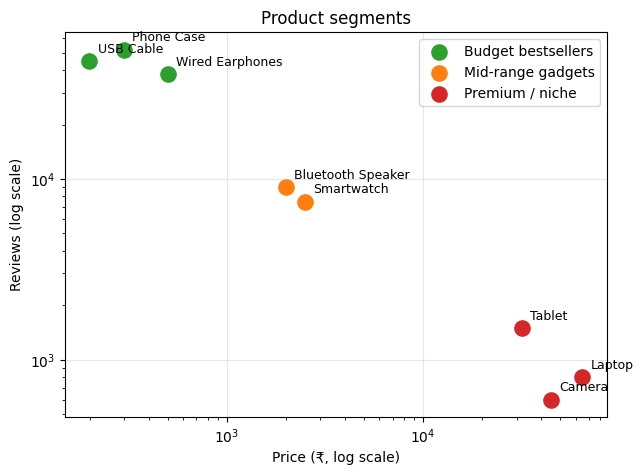

In [7]:
colors = {"Budget bestsellers": "tab:green", "Mid-range gadgets": "tab:orange", "Premium / niche": "tab:red"}
plt.figure(figsize=(7, 5))
for seg, g in products.groupby("segment"):
    plt.scatter(g["price"], g["reviews"], s=120, c=colors[seg], label=seg)
    for _, r in g.iterrows():
        plt.annotate(r["product"], (r["price"], r["reviews"]), textcoords="offset points", xytext=(6, 6), fontsize=9)
plt.xscale("log"); plt.yscale("log")
plt.xlabel("Price (₹, log scale)"); plt.ylabel("Reviews (log scale)")
plt.title("Product segments"); plt.legend(); plt.grid(alpha=.3); plt.show()

In [8]:
products.groupby("segment").agg(items=("product", lambda s: ", ".join(s)),
                                avg_price=("price", "mean"), avg_reviews=("reviews", "mean")).round(0)

,items,avg_price,avg_reviews
segment,,,
Budget bestsellers,"USB Cable, Phone Case, Wired Earphones",332.0,45000.0
Mid-range gadgets,"Bluetooth Speaker, Smartwatch",2249.0,8250.0
Premium / niche,"Tablet, Camera, Laptop",47333.0,967.0


### Reasoning for each cluster
**Cluster 1 – Budget bestsellers (USB Cable, Phone Case, Wired Earphones):** Price under ₹500 and 38k–52k reviews each. Low price means impulse buying and high volume, so many reviews. These are everyday accessories.

**Cluster 2 – Mid-range gadgets (Bluetooth Speaker, Smartwatch):** Price around ₹2,000–2,500 with 7k–9k reviews. A considered purchase: fewer buyers than accessories, but far more than premium devices.

**Cluster 3 – Premium / niche (Tablet, Camera, Laptop):** ₹32,000–65,000 with only 600–1,500 reviews. High price means few buyers, long decision time and fewer reviews.

**Insight:** price and popularity are inversely related here – as price rises, review count falls. Use: promotions/bundles for cluster 1, comparisons and EMI offers for cluster 2, trust signals and detailed specs for cluster 3.

**4.**  
List 3 scenarios in Zomato, Flipkart, or Spotify where unsupervised learning could be used to discover hidden patterns or group users/items. For each, briefly describe what data would be needed and what insights might be found.

In [9]:
scenarios = pd.DataFrame([
    {"Platform": "Zomato",
     "Scenario": "Segment customers by ordering behaviour (K-Means)",
     "Data needed": "Orders per week, average order value, cuisine mix, order time of day, discount usage, delivery distance, ratings given",
     "Hidden patterns / insights": "Groups such as 'late-night biryani lovers', 'weekday office-lunch users', 'discount hunters', 'weekend premium diners' – used for targeted offers, push-notification timing and restaurant recommendations"},
    {"Platform": "Flipkart",
     "Scenario": "Group products/shoppers by browsing + buying patterns (clustering / association rules)",
     "Data needed": "Session click logs, cart additions, purchase history, product categories, price viewed, returns, time between purchases",
     "Hidden patterns / insights": "Clusters like 'bargain shoppers who wait for Big Billion Days', 'brand-loyal electronics buyers'; frequently co-bought items (phone + case + screen guard) for bundles and 'customers also bought' features"},
    {"Platform": "Spotify",
     "Scenario": "Cluster songs and listeners by audio features and listening history",
     "Data needed": "Audio features (tempo, energy, danceability, valence), skip rate, play counts, playlist adds, listening hours, genres",
     "Hidden patterns / insights": "Mood-based groupings (workout, focus, late-night chill), micro-genres nobody labelled, user taste communities – powers Discover Weekly style playlists and cold-start recommendations"},
])
scenarios.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index")

Platform,Scenario,Data needed,Hidden patterns / insights
Zomato,Segment customers by ordering behaviour (K-Means),"Orders per week, average order value, cuisine mix, order time of day, discount usage, delivery distance, ratings given","Groups such as 'late-night biryani lovers', 'weekday office-lunch users', 'discount hunters', 'weekend premium diners' – used for targeted offers, push-notification timing and restaurant recommendations"
Flipkart,Group products/shoppers by browsing + buying patterns (clustering / association rules),"Session click logs, cart additions, purchase history, product categories, price viewed, returns, time between purchases","Clusters like 'bargain shoppers who wait for Big Billion Days', 'brand-loyal electronics buyers'; frequently co-bought items (phone + case + screen guard) for bundles and 'customers also bought' features"
Spotify,Cluster songs and listeners by audio features and listening history,"Audio features (tempo, energy, danceability, valence), skip rate, play counts, playlist adds, listening hours, genres","Mood-based groupings (workout, focus, late-night chill), micro-genres nobody labelled, user taste communities – powers Discover Weekly style playlists and cold-start recommendations"


**Summary**
1. **Zomato – customer segmentation:** needs order frequency/value/time/cuisine data; reveals ordering personas for targeted marketing.
2. **Flipkart – shopper & product grouping:** needs click, cart and purchase logs; reveals bargain-hunter segments and co-purchase bundles.
3. **Spotify – song/listener clustering:** needs audio features and listening behaviour; reveals mood groups and micro-genres for auto playlists.

**5.**  
Find a real-world dataset (CSV or Excel) online that could be used for customer segmentation (for example, mall customers, e-commerce users, or music listeners). Share the link and describe the structure: how many features, what kind of data, and whether it's labeled or unlabeled.

*Hint: Use Kaggle, UCI Machine Learning Repository, or Google to find your dataset.*

**Dataset:** Mall Customer Segmentation Data (Kaggle)
🔗 https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python
(Alternative copy: https://www.kaggle.com/datasets/joebeachcapital/customer-segmentation)

**Structure**

| Column | Type | Description |
|---|---|---|
| CustomerID | Integer (identifier) | Unique ID – not used for clustering |
| Gender | Categorical (Male/Female) | Demographic |
| Age | Numeric | Customer age |
| Annual Income (k$) | Numeric | Yearly income in thousands of dollars |
| Spending Score (1-100) | Numeric | Score assigned by the mall from customer behaviour / spending |

- **Size:** 200 customers (rows), 5 columns → **3 useful numeric features** (Age, Income, Spending Score) + 1 categorical (Gender) + 1 ID.
- **Labeled or unlabeled?** **Unlabeled** – there is no target/segment column, which is why it suits unsupervised learning (K-Means typically finds ~5 segments).
- **Format:** CSV (`Mall_Customers.csv`).

Kaggle needs a login to download. Download `Mall_Customers.csv` and put it next to this notebook; the cell below loads the real file if present, otherwise it uses `mall_customers_sample.csv` (a synthetic 200-row sample with the same schema) so the notebook still runs.

In [10]:
import os
rng = np.random.default_rng(7)

# Create synthetic sample with the same schema (only used if the real file is missing)
if not os.path.exists("mall_customers_sample.csv"):
    groups = [(5, 25, 20, 80, 30), (35, 88, 17, 40, 25), (60, 55, 45, 50, 50), ]
    # (n, income_mean, spend_mean) style simplified generation of 5 segments
    seg = [(40, 26, 20, 77, 12), (35, 88, 18, 17, 10), (45, 55, 50, 50, 8), (40, 86, 32, 82, 8), (40, 26, 45, 20, 8)]
    rows = []
    for n, inc, _, sp, sd in seg:
        for _ in range(n):
            rows.append([rng.choice(["Male", "Female"]), int(np.clip(rng.normal(38, 12), 18, 70)),
                         int(np.clip(rng.normal(inc, 9), 15, 137)), int(np.clip(rng.normal(sp, sd), 1, 99))])
    s = pd.DataFrame(rows, columns=["Gender", "Age", "Annual Income (k$)", "Spending Score (1-100)"])
    s = s.sample(frac=1, random_state=1).reset_index(drop=True)
    s.insert(0, "CustomerID", range(1, len(s) + 1))
    s.to_csv("mall_customers_sample.csv", index=False)

path = "Mall_Customers.csv" if os.path.exists("Mall_Customers.csv") else "mall_customers_sample.csv"
print("Using:", path)
mall = pd.read_csv(path)
mall.head()

Using: mall_customers_sample.csv


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,48,104,31
1,2,Female,31,87,9
2,3,Female,39,20,75
3,4,Female,34,54,51
4,5,Male,30,15,28


In [11]:
print("Shape (rows, columns):", mall.shape)
print("\nColumn types:\n", mall.dtypes)
print("\nMissing values:\n", mall.isna().sum())
print("\nLabel/target column present? ->", any(c.lower() in ("label", "segment", "target", "cluster") for c in mall.columns))
mall.describe().round(1)

Shape (rows, columns): (200, 5)

Column types:
 CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object

Missing values:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Label/target column present? -> False


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.0,200.0,200.0,200.0
mean,100.5,36.7,53.5,48.4
std,57.9,9.9,27.3,27.2
min,1.0,18.0,15.0,1.0
25%,50.8,30.0,28.0,23.0
50%,100.5,36.0,52.0,51.0
75%,150.2,44.0,79.0,74.0
max,200.0,62.0,104.0,97.0


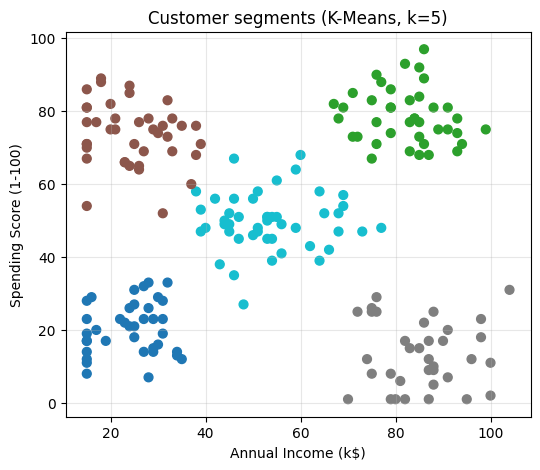

In [12]:
# Quick demo that the data is clusterable (unsupervised – no labels used)
feat = ["Annual Income (k$)", "Spending Score (1-100)"]
Xm = MinMaxScaler().fit_transform(mall[feat])
mall["cluster"] = KMeans(n_clusters=5, n_init=10, random_state=42).fit_predict(Xm)
plt.figure(figsize=(6, 5))
plt.scatter(mall[feat[0]], mall[feat[1]], c=mall["cluster"], cmap="tab10", s=40)
plt.xlabel(feat[0]); plt.ylabel(feat[1]); plt.title("Customer segments (K-Means, k=5)"); plt.grid(alpha=.3); plt.show()

## Conclusion
- Task 1: built a reproducible random dataset generator.
- Task 2: supervised learning predicts known labels; unsupervised discovers structure without them.
- Task 3: products fell into budget bestsellers, mid-range gadgets and premium/niche items.
- Task 4: Zomato, Flipkart and Spotify all have rich unlabeled behavioural data suited to clustering.
- Task 5: the Mall Customers dataset is a classic **unlabeled**, 200 × 5 dataset for segmentation.